In [1]:
import h5py
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D
from matplotlib import cm
%matplotlib inline
import os
import shutil
from ctypes import *
import random
import math
import statistics
import seaborn as sns

from baybe.parameters import CategoricalParameter, NumericalDiscreteParameter, NumericalContinuousParameter
from baybe.searchspace import SearchSpace

from baybe.targets import NumericalTarget
from baybe.objective import SingleTargetObjective
from baybe import Campaign

from baybe.recommenders import TwoPhaseMetaRecommender, RandomRecommender, BotorchRecommender
from baybe.recommenders import NaiveHybridSpaceRecommender, RandomRecommender
from baybe.recommenders.meta.sequential import TwoPhaseMetaRecommender
from baybe.constraints import (
    ContinuousLinearEqualityConstraint, ContinuousLinearInequalityConstraint, ThresholdCondition
)
from baybe.targets import NumericalTarget
np.random.seed(42)
from __future__ import annotations

import pickle
from pathlib import Path
from typing import Dict, Sequence, Tuple

import numpy as np
import matplotlib.pyplot as plt

from __future__ import annotations

import math
import pickle
from pathlib import Path
from typing import Iterable, Tuple

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import matplotlib.cm as cm
from matplotlib.font_manager import FontProperties
from matplotlib.collections import LineCollection

from baybe.parameters import NumericalContinuousParameter
from baybe.searchspace import SearchSpace
from baybe.targets import NumericalTarget
from baybe import Campaign
from baybe.recommenders import TwoPhaseMetaRecommender, RandomRecommender, BotorchRecommender
from baybe.constraints import ContinuousLinearInequalityConstraint

# NOTE: DesirabilityObjective is used below; import it explicitly
from baybe.objectives import DesirabilityObjective

In [2]:
# ----------------------------
# Configuration
# ----------------------------
ELEMENTS: Tuple[str, ...] = ("Ni", "Cr", "Nb", "Al", "Ti", "Co", "Mo")
SURROGATE_MODEL_PATH = Path("C:/Users/hasan/Uncertainty-aware-inverse-design-of-alloys/model/pce_surrogate.pkl")


# ----------------------------
# Load surrogate model
# ----------------------------
if not SURROGATE_MODEL_PATH.exists():
    raise FileNotFoundError(
        f"Surrogate model file not found: {SURROGATE_MODEL_PATH.resolve()}/n"
        "Make sure you trained and saved the PCE model first."
    )

with open(SURROGATE_MODEL_PATH, "rb") as f:
    surrogate_model = pickle.load(f)


def surrogate_predict(X: np.ndarray) -> np.ndarray:
    """
    Predict yield strength (MPa) from compositions X of shape (N, 7) in wt%.
    Expected order: [Ni, Cr, Nb, Al, Ti, Co, Mo]
    """
    X = np.asarray(X, dtype=float)
    if X.ndim != 2 or X.shape[1] != len(ELEMENTS):
        raise ValueError(f"X must have shape (N, {len(ELEMENTS)}). Got {X.shape}.")
    return surrogate_model(*X.T)

### Pareto front

In [3]:
# ----------------------------
# 5) Pareto front analysis
# ----------------------------
def pareto_front_2d(
    df: pd.DataFrame,
    xcol: str,
    ycol: str,
    maximize_x: bool = True,
    eps_x: float = 0.0,  # kept for consistency
    eps_y: float = 0.2,
) -> tuple[pd.DataFrame, np.ndarray]:
    """
    Pareto front extraction for 2 objectives:
      - maximize xcol
      - minimize ycol

    Assumes df is already filtered to only include acceptable solutions.
    """
    if df.empty:
        return df.copy(), np.zeros(0, dtype=bool)

    if xcol not in df.columns or ycol not in df.columns:
        raise KeyError(f"Columns not found. xcol='{xcol}', ycol='{ycol}'. df.columns={list(df.columns)}")

    work = df[[xcol, ycol]].copy()
    work[xcol] = pd.to_numeric(work[xcol], errors="coerce")
    work[ycol] = pd.to_numeric(work[ycol], errors="coerce")
    valid = work.dropna()

    # mask aligned to df (even if nothing is valid)
    mask = np.zeros(len(df), dtype=bool)

    if valid.empty:
        return df.iloc[0:0].copy(), mask

    arr = valid.to_numpy(dtype=float)

    order = np.argsort(-arr[:, 0]) if maximize_x else np.argsort(arr[:, 0])
    y_s = arr[order, 1]

    keep = []
    best_y = np.inf
    for k, idx in enumerate(order):
        if y_s[k] < best_y - eps_y:
            keep.append(idx)
            best_y = y_s[k]

    # keep contains positions in `valid`
    pareto_valid_index = valid.index[np.array(keep, dtype=int)]

    # IMPORTANT FIX: .isin already gives a boolean array-like; no .to_numpy() needed
    mask = np.asarray(df.index.isin(pareto_valid_index), dtype=bool)

    front = df.loc[mask].copy().sort_values(by=xcol, ascending=True)
    return front, mask



def knee_on_polyline(x: Iterable[float], y: Iterable[float]) -> int | None:
    """Return index of 'knee' point using max distance to chord heuristic."""
    x = np.asarray(list(x), float)
    y = np.asarray(list(y), float)
    if len(x) < 3:
        return None
    x0, y0 = x[0], y[0]
    x1, y1 = x[-1], y[-1]
    denom = np.hypot(x1 - x0, y1 - y0) + 1e-12
    d = np.abs((y1 - y0) * x - (x1 - x0) * y + x1 * y0 - y1 * x0) / denom
    return int(np.argmax(d))


def _trim_segment(ax, p0, p1, gap_pts: float = 6.0):
    """Trim polyline segments so lines do not run under marker circles."""
    trans = ax.transData
    inv = trans.inverted()
    P0 = trans.transform(p0)
    P1 = trans.transform(p1)
    v = P1 - P0
    L = np.hypot(v[0], v[1])
    if L <= 2 * gap_pts:
        return None
    u = v / L
    Q0 = P0 + u * gap_pts
    Q1 = P1 - u * gap_pts
    return inv.transform(Q0), inv.transform(Q1)


# ----------------------------
# 6) Visualization
# ----------------------------
def plot_pareto_front(
    df_all: pd.DataFrame,
    pareto_df: pd.DataFrame,
    xcol: str,
    ycol: str,
    cov_col: str,
    cov_min: float = 0.95,
    color_by: str | None = None,
):
    plt.rcParams["font.family"] = "calibri"

    dfc = df_all.copy()
    if (cov_col in dfc.columns) and (cov_min is not None):
        dfc = dfc[dfc[cov_col] >= cov_min].copy()

    if dfc.empty:
        print("plot_pareto_front: no data to plot.")
        return

    if color_by is None:
        color_by = cov_col if cov_col in dfc.columns else xcol

    cvals = pd.to_numeric(dfc[color_by], errors="coerce").to_numpy(float)
    norm = mcolors.Normalize(vmin=np.nanmin(cvals), vmax=np.nanmax(cvals))
    cmap = cm.viridis

    fig, ax = plt.subplots(figsize=(8, 6))
    ax.scatter(
        dfc[xcol],
        dfc[ycol],
        s=150,
        c=cvals,
        cmap=cmap,
        norm=norm,
        alpha=0.60,
        linewidths=0,
        label="Filtered designs",
    )

    if not pareto_df.empty:
        ax.scatter(
            pareto_df[xcol],
            pareto_df[ycol],
            s=200,
            facecolor="none",
            edgecolor="k",
            linewidths=1.2,
            zorder=3,
            label="Pareto designs",
        )

        segments = []
        if len(pareto_df) >= 2:
            fig.canvas.draw()
            for i in range(len(pareto_df) - 1):
                p0 = (pareto_df.iloc[i][xcol], pareto_df.iloc[i][ycol])
                p1 = (pareto_df.iloc[i + 1][xcol], pareto_df.iloc[i + 1][ycol])
                trimmed = _trim_segment(ax, p0, p1, gap_pts=8.0)
                if trimmed is not None:
                    q0, q1 = trimmed
                    segments.append([q0, q1])

        if segments:
            lc = LineCollection(segments, colors=["C0"], linewidths=4, zorder=2)
            lc.set_label("Pareto front")
            ax.add_collection(lc)

        knee_idx = knee_on_polyline(pareto_df[xcol], pareto_df[ycol])
        if knee_idx is not None:
            ax.scatter(
                pareto_df.iloc[knee_idx][xcol],
                pareto_df.iloc[knee_idx][ycol],
                s=180,
                facecolor="gold",
                edgecolor="k",
                linewidths=1.2,
                zorder=4,
                label="Knee",
            )

    ax.set_xlabel("Expected strength LCB₉₅ over box (5th percentile) (MPa)", fontsize=18, fontweight="bold")
    ax.set_ylabel("Total uncertainty (MPa)", fontsize=18, fontweight="bold")

    legend_prop = FontProperties(size=14, weight="bold")
    ax.legend(frameon=False, loc="best", prop=legend_prop)

    sm = cm.ScalarMappable(norm=norm, cmap=cmap)
    cbar = plt.colorbar(sm, ax=ax, pad=0.02)
    cbar.set_label(color_by, fontsize=16, fontweight="bold")

    plt.tight_layout()
    plt.show()

In [4]:
Alloy718 = pd.read_csv("C:/Users/hasan/Uncertainty-aware-inverse-design-of-alloys/Data/Example dataset of Alloy 718 strength.csv")
Alloy718 = Alloy718.drop(['Unnamed: 0'], axis = 1)
Alloy718.describe()

,Ni (wt%),Cr (wt%),Nb (wt%),Al (wt%),Ti (wt%),Co (wt%),Mo (wt%),γ′(mole %),γ′′(mole %),Solid solution strength (MPa),Orowan strength (MPa),Coherent strain strength,Yield strength (MPa)
count,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000
mean,52.496497,19.001691,5.124952,0.502052,0.897332,0.498538,3.050125,9.820214,8.940168,220.530232,605.279352,271.639340,1186.445644
std,1.450452,1.158926,0.216341,0.173115,0.144314,0.289863,0.144351,3.882546,2.754503,5.385558,194.844674,60.232421,144.715774
min,50.000077,17.000444,4.750029,0.200014,0.650073,0.000009,2.800135,1.299378,1.827952,212.946910,153.813288,98.127758,805.834998
25%,51.248291,17.996188,4.938664,0.353178,0.773637,0.245387,2.926132,6.699164,6.773779,216.284725,452.628421,226.227733,1078.654215
50%,52.488655,19.007600,5.121810,0.503962,0.895244,0.499752,3.050152,9.914901,8.819983,219.203145,607.097402,270.722729,1185.369237
75%,53.750816,20.004760,5.313983,0.651815,1.021043,0.752141,3.174693,12.882105,11.089508,223.462083,754.957475,317.286712,1290.674964
max,54.999954,20.999204,5.499837,0.799986,1.149920,0.999899,3.299962,18.671690,15.489290,245.996120,1103.446042,423.663362,1611.964731


## 2nd version

Running BO iteration 1/10
Running BO iteration 2/10


c:\Users\hasan\.conda\envs\ML\Lib\site-packages\botorch\models\utils\assorted.py:260: InputDataWarning: Data is not standardized (std = tensor([0.]), mean = tensor([0.])). Please consider scaling the input to zero mean and unit variance.
  check_standardization(Y=train_Y, raise_on_fail=raise_on_fail)


Running BO iteration 3/10
Running BO iteration 4/10
Running BO iteration 5/10
Running BO iteration 6/10
Running BO iteration 7/10
Running BO iteration 8/10
Running BO iteration 9/10
Running BO iteration 10/10

Saved: outputs\bo_measurements_full.csv
Saved: outputs\pareto_filtered.csv
Saved (not displayed): outputs\pareto_front.csv

Filtered dataset (final output):
       Ni_min     Ni_max     Cr_min     Cr_max    Nb_min    Nb_max    Al_min    Al_max    Ti_min    Ti_max    Co_min    Co_max    Mo_min    Mo_max  Predicted yield strength (MPa)  \
0   50.000078  51.577376  19.827748  20.372326  4.964292  5.032392  0.200014  0.250014  1.099920  1.149920  0.503007  0.553007  2.800135  3.288967                     1082.423258   
1   50.050677  51.643002  19.749782  19.905058  4.969469  5.051022  0.206017  0.256096  1.099920  1.149920  0.544495  0.665530  2.800563  3.299962                     1083.472996   
2   50.060647  51.375092  20.146711  20.196711  4.998059  5.094390  0.203074  0.253482 

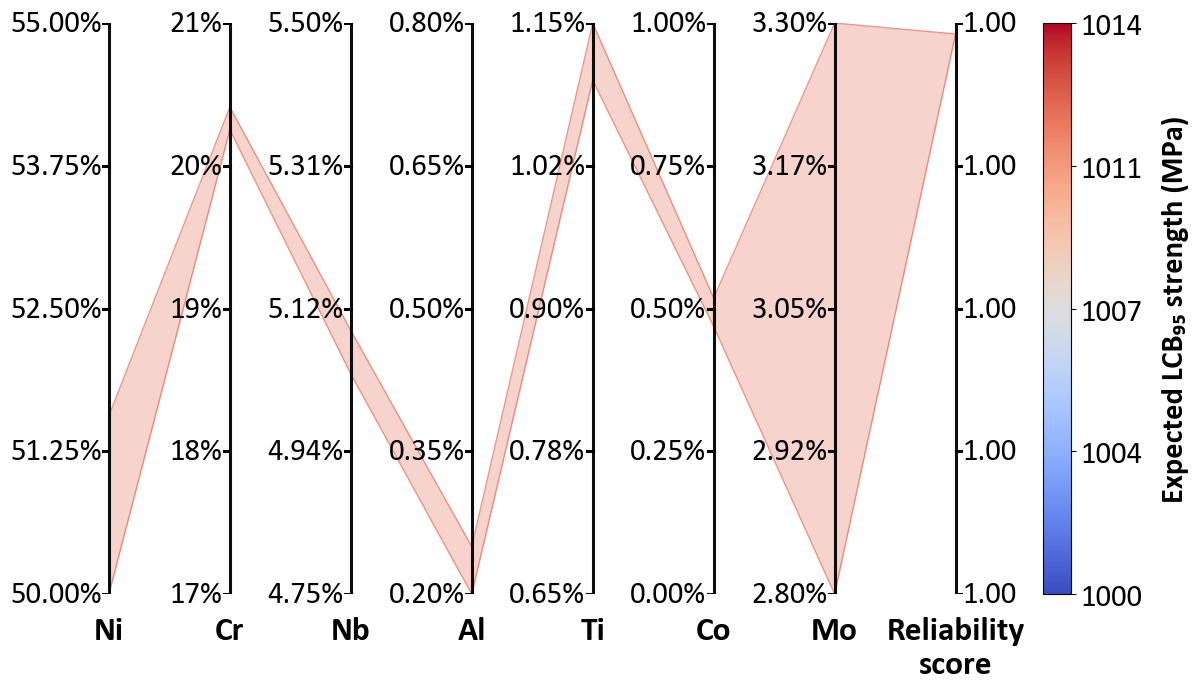

In [ ]:
# ----------------------------
# Configuration
# ----------------------------
ELEMENTS: Tuple[str, ...] = ("Ni", "Cr", "Nb", "Al", "Ti", "Co", "Mo")

DATASET_PATH = Path(
    "C:/Users/hasan/Uncertainty-aware-inverse-design-of-alloys/data/Example dataset of Alloy 718 strength.csv"
)
SURROGATE_MODEL_PATH = Path(
    "C:/Users/hasan/Uncertainty-aware-inverse-design-of-alloys/model/pce_surrogate.pkl"
)

# Defaults you do NOT want to prompt for
DEFAULT_NUM_MC_SAMPLES = 1000
DEFAULT_SIGMA_MODEL = 32.417
DEFAULT_Z_INNER = 1.645

DEFAULT_RANGES_WT = {
    "Ni": (50.0, 55.0),
    "Cr": (17.0, 21.0),
    "Nb": (4.75, 5.50),
    "Al": (0.2, 0.8),
    "Ti": (0.65, 1.15),
    "Co": (0.0, 1.0),
    "Mo": (2.8, 3.3),
}

OUTPUT_DIR = Path("outputs")


# ---------------------------------------------------------
# 1) Loading helpers
# ---------------------------------------------------------
def load_dataset_for_bounds(path: Path) -> pd.DataFrame:
    if not path.exists():
        raise FileNotFoundError(f"Dataset file not found: {path.resolve()}")
    return pd.read_csv(path)


def load_surrogate_model(path: Path):
    if not path.exists():
        raise FileNotFoundError(f"Surrogate model not found: {path.resolve()}")
    with open(path, "rb") as f:
        return pickle.load(f)


# ---------------------------------------------------------
# 2) Helper functions: Wilson / sampling / QoI calculations
# ---------------------------------------------------------
def _wilson_lower_95(p_hat: float, n: int) -> float:
    """Wilson score lower bound for a binomial proportion (fixed 95% CI)."""
    if n <= 0:
        return 0.0
    z = 1.959963984540054
    denom = 1.0 + z**2 / n
    center = (p_hat + z**2 / (2 * n)) / denom
    radius = (z / denom) * math.sqrt((p_hat * (1 - p_hat) + z**2 / (4 * n)) / n)
    return max(0.0, center - radius)


def _uniform_range(lo: float, hi: float, n: int) -> np.ndarray:
    """Sample uniformly from [lo, hi] robustly."""
    lo = float(lo)
    hi = float(hi)
    if hi < lo:
        lo, hi = hi, lo
    return np.random.uniform(lo, hi, int(n))


def suggest_range_with_coverage(
    dataframe: pd.DataFrame,
    num_samples: int,
    model,
    sigma_model: float,
    target_YS: float,
    z_inner: float = DEFAULT_Z_INNER,
) -> Tuple[list, list, list, list, list, list]:
    """
    For each candidate box (row with *_min/*_max for ALL 7 elements), sample compositions,
    predict strength, and compute:
      - mean strength
      - compositional variation std(mu)
      - total uncertainty sqrt(std(mu)^2 + sigma_model^2)
      - 5th percentile of LCB: quantile(mu - z*sigma_model, 0.05)
      - coverage p_x: fraction with (mu - z*sigma_model >= target_YS)
      - Wilson lower bound (95% CI)
    """
    required_cols = []
    for el in ELEMENTS:
        required_cols += [f"{el}_min", f"{el}_max"]
    missing = [c for c in required_cols if c not in dataframe.columns]
    if missing:
        raise KeyError(f"Candidate dataframe missing required columns: {missing}")

    mean_strength, sigma_prop, sigma_total = [], [], []
    lb05_over_box, coverage_prop, coverage_lb = [], [], []

    sigma_model = float(sigma_model)
    target_YS = float(target_YS)

    for _, row in dataframe.iterrows():
        samples = []
        for el in ELEMENTS:
            samples.append(_uniform_range(row[f"{el}_min"], row[f"{el}_max"], num_samples))
        X = np.vstack(samples).T  # (N, 7)

        mu_i = np.asarray(model(*X.T), dtype=float).reshape(-1)

        lcb_i = mu_i - z_inner * sigma_model
        safe = (lcb_i >= target_YS)
        p_hat = float(np.mean(safe))
        p_lb = _wilson_lower_95(p_hat, len(mu_i))

        q05_lb = float(np.quantile(lcb_i, 0.05))

        s_comp = float(np.std(mu_i, ddof=1))
        s_tot = math.sqrt(s_comp**2 + sigma_model**2)

        mean_strength.append(float(np.mean(mu_i)))
        sigma_prop.append(s_comp)
        sigma_total.append(s_tot)
        lb05_over_box.append(q05_lb)
        coverage_prop.append(p_hat)
        coverage_lb.append(p_lb)

    return (mean_strength, sigma_prop, sigma_total, lb05_over_box, coverage_prop, coverage_lb)


# ---------------------------------------------------------
# 3) BayBE: search space + campaign
# ---------------------------------------------------------
def build_searchspace(
    df: pd.DataFrame,
    *,
    min_deltas: Dict[str, float],
) -> SearchSpace:
    """
    Search variables are min/max for each element; bounds are derived from dataset columns:
      '{El} (wt%)' for each El in ELEMENTS.

    min_deltas:
      dict mapping element -> minimum allowable (max-min) difference for that element.
    """
    def _bounds(col: str) -> Tuple[float, float]:
        a = pd.to_numeric(df[col], errors="coerce")
        lo = float(np.nanmin(a.to_numpy(dtype=float)))
        hi = float(np.nanmax(a.to_numpy(dtype=float)))
        if not np.isfinite(lo) or not np.isfinite(hi) or hi <= lo:
            raise ValueError(f"Bad bounds from column '{col}': lo={lo}, hi={hi}")
        return (lo, hi)

    # parameters
    params = []
    for el in ELEMENTS:
        col = f"{el} (wt%)"
        lo, hi = _bounds(col)
        params.append(NumericalContinuousParameter(f"{el}_min", bounds=(lo, hi)))
        params.append(NumericalContinuousParameter(f"{el}_max", bounds=(lo, hi)))

    # constraints: max >= min + eps(el)
    constraints = []
    for el in ELEMENTS:
        eps = float(min_deltas[el])
        if eps <= 0:
            raise ValueError(f"Minimum allowable difference for {el} must be > 0. Got {eps}.")
        constraints.append(
            ContinuousLinearInequalityConstraint(
                parameters=[f"{el}_max", f"{el}_min"],
                coefficients=[1.0, -1.0],
                rhs=eps,
            )
        )

    return SearchSpace.from_product(parameters=params, constraints=constraints)


def build_campaign(
    space: SearchSpace,
    *,
    min_required_strength: float,
    sigma_threshold: float,
    reliability_target: float,
    weights: Tuple[float, float, float],
) -> Campaign:
    min_required_strength = float(min_required_strength)
    sigma_threshold = float(sigma_threshold)
    reliability_target = float(reliability_target)

    if sigma_threshold <= 0:
        raise ValueError("sigma_threshold must be > 0.")
    if not (0.0 < reliability_target <= 1.0):
        raise ValueError("reliability_target must be in (0, 1].")

    w1, w2, w3 = map(float, weights)
    wsum = w1 + w2 + w3
    if wsum <= 0:
        raise ValueError("Weights must sum to a positive value.")
    weights_norm = [w1 / wsum, w2 / wsum, w3 / wsum]

    lb_lo = min_required_strength
    lb_hi = min_required_strength + 0.5 * sigma_threshold

    obj_1 = NumericalTarget(
        name="Total uncertainty",
        mode="MIN",
        bounds=(0.0, sigma_threshold),
        transformation="LINEAR",
    )
    obj_2 = NumericalTarget(
        name="Coverage over box p_x",
        mode="MATCH",
        bounds=(reliability_target, 1.0),
        transformation="TRIANGULAR",
    )
    obj_3 = NumericalTarget(
        name="Percentile LB over box (5%) (MPa)",
        mode="MATCH",
        bounds=(lb_lo, lb_hi),
        transformation="BELL",
    )

    objective = DesirabilityObjective(
        targets=[obj_1, obj_2, obj_3],
        weights=weights_norm,
        scalarizer="GEOM_MEAN",
    )

    recommender = TwoPhaseMetaRecommender(
        initial_recommender=RandomRecommender(),
        recommender=BotorchRecommender(acquisition_function="qLogEI"),
    )

    return Campaign(searchspace=space, objective=objective, recommender=recommender)


# ---------------------------------------------------------
# 4) Run Bayesian optimization
# ---------------------------------------------------------
def run_bayesian_optimization(
    campaign: Campaign,
    model,
    *,
    n_iters: int,
    batch_size: int,
    num_mc_samples: int,
    target_YS: float,
    sigma_model: float,
    z_inner: float,
    lb_window: Tuple[float, float],
    sigma_max: float,
    coverage_min: Optional[float],
) -> Tuple[pd.DataFrame, pd.DataFrame]:
    if n_iters <= 0:
        raise ValueError("n_iters must be positive.")
    if batch_size <= 0:
        raise ValueError("batch_size must be positive.")
    if num_mc_samples <= 0:
        raise ValueError("num_mc_samples must be positive.")

    for k in range(n_iters):
        print(f"Running BO iteration {k + 1}/{n_iters}")
        iter_df = campaign.recommend(batch_size=batch_size)

        mu, s_comp, s_tot, lb5, cover_p, cover_lb = suggest_range_with_coverage(
            dataframe=iter_df,
            num_samples=num_mc_samples,
            model=model,
            sigma_model=sigma_model,
            target_YS=target_YS,
            z_inner=z_inner,
        )

        iter_df["Predicted yield strength (MPa)"] = mu
        iter_df["Compositional variation"] = s_comp
        iter_df["Total uncertainty"] = s_tot
        iter_df["Percentile LB over box (5%) (MPa)"] = lb5
        iter_df["Coverage over box p_x"] = cover_p
        iter_df["Coverage over box LB (95% CI)"] = cover_lb

        campaign.add_measurements(iter_df)

    full_data = campaign.measurements.copy()

    mask = (
        full_data["Percentile LB over box (5%) (MPa)"].between(lb_window[0], lb_window[1], inclusive="both")
        & (full_data["Total uncertainty"] <= sigma_max)
    )
    if coverage_min is not None:
        mask &= (full_data["Coverage over box p_x"] >= float(coverage_min))

    filtered_data = (
        full_data.loc[mask]
        .sort_values("Total uncertainty", ascending=True)
        .reset_index(drop=True)
    )
    return full_data, filtered_data


# ---------------------------------------------------------
# 5) Pareto front analysis (2D)
# ---------------------------------------------------------
def pareto_front_2d(
    df: pd.DataFrame,
    xcol: str,
    ycol: str,
    maximize_x: bool = True,
    eps_y: float = 0.2,
) -> Tuple[pd.DataFrame, np.ndarray]:
    if df.empty:
        return df.copy(), np.zeros(0, dtype=bool)

    work = df[[xcol, ycol]].copy()
    work[xcol] = pd.to_numeric(work[xcol], errors="coerce")
    work[ycol] = pd.to_numeric(work[ycol], errors="coerce")
    valid = work.dropna()

    if valid.empty:
        return df.iloc[0:0].copy(), np.zeros(len(df), dtype=bool)

    arr = valid.to_numpy(dtype=float)

    order = np.argsort(-arr[:, 0]) if maximize_x else np.argsort(arr[:, 0])
    y_sorted = arr[order, 1]

    keep_pos = []
    best_y = np.inf
    for k, pos in enumerate(order):
        if y_sorted[k] < best_y - float(eps_y):
            keep_pos.append(pos)
            best_y = y_sorted[k]

    pareto_valid_index = valid.index[np.array(keep_pos, dtype=int)]
    mask = df.index.isin(pareto_valid_index)
    front = df.loc[mask].copy().sort_values(by=xcol, ascending=True)
    return front, np.asarray(mask, dtype=bool)


# ---------------------------------------------------------
# 6) Coordinate (parallel-axes) plot for ONE design row
# ---------------------------------------------------------
def plot_coordinate_plot_single_row_like_reference(
    row: pd.Series,
    *,
    # use pareto_df ONLY to define the PROPERTY-axis range (ticks/labels), exactly like your reference
    pareto_df: pd.DataFrame,
    target_YS: float,
    out_path: Path | None = None,
    elements: list[str] | None = None,
    ranges_wt: dict[str, tuple[float, float]] | None = None,
    strength_col: str = "Percentile LB over box (5%) (MPa)",     # colorbar
    coverage_candidates: tuple[str, ...] = ("Coverage over p_box", "Coverage over box p_x"),
    prop_axis_label: str = "Reliability\nscore",
    cb_label: str = "Expected LCB₉₅ strength (MPa)",
    fig_size: tuple[float, float] = (12.5, 7.0),
    # Co-axis tick customization
    co_ticks: np.ndarray | None = None,
    co_tick_format: str | None = "{:.2f}%",
) -> plt.Figure:
    """
    Single-row coordinate (parallel-axes) plot that matches your reference plot style:
    - element axes show wt% tick labels on the LEFT of each vertical axis
    - reliability axis shows tick labels on the RIGHT of the last axis
    - colorbar uses strength_col with limits/ticks derived like your reference
    - property axis range is derived from pareto_df[coverage_col] (not from the single row)

    Saves to out_path if provided and returns fig.
    """
    import numpy as np
    import pandas as pd
    import matplotlib.pyplot as plt
    import matplotlib.cm as cm
    import matplotlib.colors as mcolors
    from matplotlib.font_manager import FontProperties

    if elements is None:
        elements = list(ELEMENTS)
    if ranges_wt is None:
        ranges_wt = DEFAULT_RANGES_WT

    # ---- coverage column selection (same logic as your reference) ----
    coverage_col = None
    for cname in coverage_candidates:
        if cname in pareto_df.columns:
            coverage_col = cname
            break
    if coverage_col is None:
        raise KeyError(
            f"None of the coverage columns {list(coverage_candidates)} were found in pareto_df.columns="
            f"{list(pareto_df.columns)}"
        )
    if coverage_col not in row.index:
        raise KeyError(
            f"Coverage column '{coverage_col}' not found in selected row index={row.name}. "
            f"Row has columns: {list(row.index)}"
        )
    if strength_col not in row.index:
        raise KeyError(f"strength_col '{strength_col}' not found in selected row index={row.name}.")

    # ---- required min/max columns ----
    missing = []
    for el in elements:
        for suf in ("_min", "_max"):
            c = f"{el}{suf}"
            if c not in row.index:
                missing.append(c)
    if missing:
        raise KeyError(f"Selected row is missing required range columns: {missing}")

    # ---- plot_df contains rows to plot: SINGLE ROW only ----
    plot_df = pd.DataFrame([row]).copy()

    # numeric coercion (safety)
    plot_df[strength_col] = pd.to_numeric(plot_df[strength_col], errors="coerce")
    plot_df[coverage_col] = pd.to_numeric(plot_df[coverage_col], errors="coerce")
    if plot_df[strength_col].isna().all():
        raise ValueError(f"'{strength_col}' is NaN after numeric coercion for this row.")
    if plot_df[coverage_col].isna().all():
        raise ValueError(f"'{coverage_col}' is NaN after numeric coercion for this row.")

    # ------------------ reference-style constants ------------------
    plt.rcParams["font.family"] = "calibri"

    cmap = cm.coolwarm

    # Strength colorbar limits/ticks like your reference:
    # vmin = target_YS
    # vmax = max pareto strength (or fallback to row strength)
    pareto_strength = pd.to_numeric(pareto_df.get(strength_col, pd.Series([], dtype=float)), errors="coerce").to_numpy(
        dtype=float
    )
    vmax_ref = float(np.nanmax(pareto_strength)) if pareto_strength.size else float(plot_df[strength_col].iloc[0])
    if not np.isfinite(vmax_ref):
        vmax_ref = float(plot_df[strength_col].iloc[0])

    vmin = float(target_YS)
    vmax = float(max(vmin + 1e-6, vmax_ref))
    cnorm = mcolors.Normalize(vmin=vmin, vmax=vmax)
    strength_cbar_ticks = np.linspace(vmin, vmax, 5)

    # Typography controls (same as reference)
    X_LABEL_FONT = {"size": 24, "weight": "bold", "color": "black"}
    X_LABEL_PAD = 16

    AX_TICK_FONT = {"size": 22, "weight": "normal", "color": "black"}
    TICK_LEN = 0.045
    TICK_LW = 2.2
    TICK_COLOR = "black"
    LABEL_DX_LEFT = 0.060
    LABEL_DX_RIGHT = 0.060

    # Co ticks
    if co_ticks is None:
        co_ticks = np.array([0.00, 0.25, 0.50, 0.75, 1.00], dtype=float)

    # ------------------ helpers (copied behavior) ------------------
    def to_axis_units(v, el):
        v = float(v)
        hi = ranges_wt[el][1]
        if v <= 1.5 and hi > 2.0:
            return v * 180.0
        return v

    def norm_to_range(value, lo, hi):
        return (np.asarray(value, float) - lo) / (hi - lo + 1e-12)

    # ticks per axis (reference style)
    axis_ticks = {el: np.linspace(ranges_wt[el][0], ranges_wt[el][1], 5) for el in elements}
    axis_ticks["Co"] = np.asarray(co_ticks, float)

    # internal property axis key (compat)
    prop_axis_name = "LB (5%)"  # internal key for logic/helpers

    def get_ticks_for_axis(name, lo, hi):
        if name == prop_axis_name:
            return np.linspace(lo, hi, 5)
        return np.asarray(axis_ticks.get(name, np.linspace(lo, hi, 5)), float)

    def format_tick_label(name, t_val, ticks):
        if name == prop_axis_name:
            return f"{t_val:.2f}"
        if name == "Co" and co_tick_format:
            return co_tick_format.format(t_val)
        return "{:.0f}%".format(t_val) if np.allclose(ticks, np.round(ticks), atol=1e-9) else "{:.2f}%".format(t_val)

    # ------------------ axis order & PROPERTY range from pareto_df coverage ------------------
    axis_labels = elements + [prop_axis_label]
    prop_axis_index = len(elements)

    cov_vals = pd.to_numeric(pareto_df[coverage_col], errors="coerce").to_numpy(dtype=float)
    vmin_prop = float(np.nanmin(cov_vals))
    vmax_prop = float(np.nanmax(cov_vals))
    if not np.isfinite(vmin_prop) or not np.isfinite(vmax_prop):
        vmin_prop, vmax_prop = 0.0, 1.0
    if vmin_prop == vmax_prop:
        eps = max(1e-6, 1e-6 * max(1.0, abs(vmin_prop)))
        vmin_prop -= eps
        vmax_prop += eps
    pad = 0.02 * (vmax_prop - vmin_prop + 1e-12)
    prop_range = (vmin_prop - pad, vmax_prop + pad)

    x = np.arange(len(axis_labels))

    # ------------------ plot ------------------------
    fig, ax = plt.subplots(figsize=fig_size)

    # draw bands/lines for the SINGLE ROW, but using the same approach as reference
    for _, r in plot_df.iterrows():
        y_min = []
        y_max = []

        for el in elements:
            vmin_el = to_axis_units(r[f"{el}_min"], el)
            vmax_el = to_axis_units(r[f"{el}_max"], el)
            y_min.append(norm_to_range(vmin_el, *ranges_wt[el]))
            y_max.append(norm_to_range(vmax_el, *ranges_wt[el]))

        cov_val = float(r[coverage_col])
        y_prop = norm_to_range(cov_val, *prop_range)
        y_min.append(y_prop)
        y_max.append(y_prop)

        y_min = np.array(y_min, float)
        y_max = np.array(y_max, float)
        y_lo = np.minimum(y_min, y_max)
        y_hi = np.maximum(y_min, y_max)

        color = cmap(cnorm(float(r[strength_col])))
        ax.fill_between(x, y_lo, y_hi, color=color, alpha=0.30, linewidth=0)
        ax.plot(x, y_lo, color=color, alpha=0.7, linewidth=1.0)
        ax.plot(x, y_hi, color=color, alpha=0.7, linewidth=1.0)

    # cosmetics
    ax.set_xlim(-0.25, len(axis_labels) - 0.75)
    ax.set_ylim(0, 1)
    ax.set_yticks([])

    ax.set_xticks(x)
    texts = ax.set_xticklabels(axis_labels)
    for t in texts:
        t.set_fontsize(X_LABEL_FONT.get("size", 12))
        t.set_fontweight(X_LABEL_FONT.get("weight", "normal"))
        t.set_color(X_LABEL_FONT.get("color", "black"))
    ax.tick_params(axis="x", length=0, pad=X_LABEL_PAD)

    for side in ("left", "right", "top", "bottom"):
        ax.spines[side].set_visible(False)

    for xi in x:
        ax.vlines(xi, 0, 1, color="black", linewidth=2.2, alpha=0.95)

    # tick marks + numeric labels (LEFT for elements, RIGHT for property axis)
    for xi, nm_display in enumerate(axis_labels):
        is_prop = (xi == prop_axis_index)
        name_for_logic = prop_axis_name if is_prop else nm_display

        if is_prop:
            lo, hi = prop_range
        else:
            lo, hi = ranges_wt[name_for_logic]

        ticks = get_ticks_for_axis(name_for_logic, lo, hi)
        y_ticks = (ticks - lo) / (hi - lo + 1e-12)

        if is_prop:
            for t_val, yv in zip(ticks, y_ticks):
                ax.plot([xi, xi + TICK_LEN], [yv, yv], color=TICK_COLOR, linewidth=TICK_LW)
                ax.text(
                    xi + LABEL_DX_RIGHT,
                    yv,
                    format_tick_label(name_for_logic, t_val, ticks),
                    ha="left",
                    va="center",
                    fontsize=AX_TICK_FONT.get("size", 20),
                    fontweight=AX_TICK_FONT.get("weight", "normal"),
                    color=AX_TICK_FONT.get("color", "black"),
                    clip_on=False,
                )
        else:
            for t_val, yv in zip(ticks, y_ticks):
                ax.plot([xi - TICK_LEN, xi], [yv, yv], color=TICK_COLOR, linewidth=TICK_LW)
                ax.text(
                    xi - LABEL_DX_LEFT,
                    yv,
                    format_tick_label(name_for_logic, t_val, ticks),
                    ha="right",
                    va="center",
                    fontsize=AX_TICK_FONT.get("size", 18),
                    fontweight=AX_TICK_FONT.get("weight", "normal"),
                    color=AX_TICK_FONT.get("color", "black"),
                    clip_on=False,
                )

    # ------------------ colorbar ------------------
    # extend logic based on the plotted subset (single row)
    subset_vals = plot_df[strength_col].to_numpy(float)
    extend = (
        "both"
        if (np.nanmin(subset_vals) < vmin and np.nanmax(subset_vals) > vmax)
        else "min"
        if np.nanmin(subset_vals) < vmin
        else "max"
        if np.nanmax(subset_vals) > vmax
        else "neither"
    )

    plt.subplots_adjust(left=0.22, right=0.90, bottom=0.16)
    sm = cm.ScalarMappable(norm=cnorm, cmap=cmap)
    cbar = plt.colorbar(sm, ax=ax, pad=0.05, extend=extend)

    cb_label_props = FontProperties(size=22, weight="bold")
    cbar.ax.set_ylabel(cb_label, fontproperties=cb_label_props, rotation=90, labelpad=14)

    cbar.ax.tick_params(labelsize=22, labelcolor="black")
    for lbl in cbar.ax.get_yticklabels():
        lbl.set_fontweight("normal")

    cbar.set_ticks(strength_cbar_ticks)
    cbar.set_ticklabels([f"{t:.0f}" for t in strength_cbar_ticks])

    plt.subplots_adjust(left=0.22, right=0.92, bottom=0.16)
    plt.tight_layout()

    if out_path is not None:
        out_path.parent.mkdir(parents=True, exist_ok=True)
        fig.savefig(out_path, dpi=300, bbox_inches="tight")

    return fig



# ---------------------------------------------------------
# 7) CLI prompts + main
# ---------------------------------------------------------
def _prompt_float(prompt: str, default: float | None = None) -> float:
    while True:
        raw = input(f"{prompt}" + (f" [default={default}]: " if default is not None else ": ")).strip()
        if raw == "" and default is not None:
            return float(default)
        try:
            return float(raw)
        except ValueError:
            print("Please enter a valid number.")


def _prompt_int(prompt: str, default: int | None = None) -> int:
    while True:
        raw = input(f"{prompt}" + (f" [default={default}]: " if default is not None else ": ")).strip()
        if raw == "" and default is not None:
            return int(default)
        try:
            v = int(raw)
            if v <= 0:
                print("Please enter a positive integer.")
                continue
            return v
        except ValueError:
            print("Please enter a valid integer.")


def _prompt_weights(default=(0.5, 0.3, 0.2)) -> Tuple[float, float, float]:
    while True:
        raw = input(f"Enter objective weights w1,w2,w3 [default={default}]: ").strip()
        if raw == "":
            return (float(default[0]), float(default[1]), float(default[2]))
        parts = [p.strip() for p in raw.split(",")]
        if len(parts) != 3:
            print("Please enter exactly 3 comma-separated numbers, e.g., 0.5,0.3,0.2")
            continue
        try:
            w = tuple(float(p) for p in parts)
            if sum(w) <= 0:
                print("Weights must sum to a positive value.")
                continue
            return w
        except ValueError:
            print("Please enter valid numbers for weights.")


def _prompt_min_deltas() -> Dict[str, float]:
    """
    Prompts for minimum allowable (max-min) differences.

    You can enter:
      - one number: applies to all elements
      - seven comma-separated numbers: applies in order ELEMENTS
    """
    while True:
        raw = input(
            "Minimum allowable difference (max-min). Enter one value for all elements "
            "or 7 comma-separated values for Ni,Cr,Nb,Al,Ti,Co,Mo [default=0.01]: "
        ).strip()
        if raw == "":
            return {el: 0.01 for el in ELEMENTS}

        parts = [p.strip() for p in raw.split(",") if p.strip() != ""]
        try:
            if len(parts) == 1:
                v = float(parts[0])
                if v <= 0:
                    print("Value must be > 0.")
                    continue
                return {el: v for el in ELEMENTS}
            if len(parts) == len(ELEMENTS):
                vals = [float(p) for p in parts]
                if any(v <= 0 for v in vals):
                    print("All values must be > 0.")
                    continue
                return {el: v for el, v in zip(ELEMENTS, vals)}
            print("Please enter either 1 value or exactly 7 comma-separated values.")
        except ValueError:
            print("Please enter valid numeric values.")


def _prompt_plot_row_index(n_rows: int) -> Optional[int]:
    """
    Ask for which row index to plot.
    - Enter / Esc / q => skip
    - Otherwise must be an integer in [0, n_rows-1]
    """
    while True:
        raw = input(
            f"\nEnter a filtered_df row index to plot (0..{n_rows-1}), "
            "or press Enter / type 'q' / type 'esc' to skip: "
        )
        if raw is None:
            return None
        s = raw.strip().lower()
        if s in ("", "q", "quit", "esc", "escape"):
            return None
        try:
            idx = int(s)
            if 0 <= idx < n_rows:
                return idx
            print("Index out of range.")
        except ValueError:
            print("Please enter a valid integer index, or Enter/q/esc to skip.")


def main() -> None:
    # load
    df_bounds = load_dataset_for_bounds(DATASET_PATH)
    surrogate_model = load_surrogate_model(SURROGATE_MODEL_PATH)

    # user inputs
    min_required_strength = _prompt_float("Minimum required strength (MPa)", default=1000.0)
    sigma_threshold = _prompt_float("Allowable total uncertainty threshold (MPa)", default=45.0)
    reliability_pct = _prompt_float("Target reliability (%)", default=95.0)

    reliability_target = reliability_pct / 100.0 if reliability_pct > 1.0 else reliability_pct
    if not (0.0 < reliability_target <= 1.0):
        raise ValueError("Reliability must be given as 0-1 or 0-100%.")

    weights = _prompt_weights(default=(0.5, 0.3, 0.2))

    n_iters = _prompt_int("Number of BO iterations", default=10)
    batch_size = _prompt_int("Batch size per iteration", default=10)

    # new requirement: min allowable difference per element
    min_deltas = _prompt_min_deltas()

    # fixed defaults (no prompts)
    num_mc_samples = DEFAULT_NUM_MC_SAMPLES
    sigma_model = DEFAULT_SIGMA_MODEL
    z_inner = DEFAULT_Z_INNER

    # derived
    lb_lo = float(min_required_strength)
    lb_hi = float(min_required_strength + 0.5 * sigma_threshold)
    lb_window = (lb_lo, lb_hi)

    target_YS = float(min_required_strength)
    sigma_max = float(sigma_threshold)
    coverage_min = float(reliability_target)

    # build BO
    space = build_searchspace(df_bounds, min_deltas=min_deltas)
    campaign = build_campaign(
        space,
        min_required_strength=min_required_strength,
        sigma_threshold=sigma_threshold,
        reliability_target=reliability_target,
        weights=weights,
    )

    OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

    full_df, filtered_df = run_bayesian_optimization(
        campaign=campaign,
        model=surrogate_model,
        n_iters=n_iters,
        batch_size=batch_size,
        num_mc_samples=num_mc_samples,
        target_YS=target_YS,
        sigma_model=sigma_model,
        z_inner=z_inner,
        lb_window=lb_window,
        sigma_max=sigma_max,
        coverage_min=coverage_min,
    )

    # save full + filtered (but only SHOW filtered)
    full_path = OUTPUT_DIR / "bo_measurements_full.csv"
    filt_path = OUTPUT_DIR / "pareto_filtered.csv"  # per your new naming requirement
    full_df.to_csv(full_path, index=False)
    filtered_df.to_csv(filt_path, index=False)

    print(f"\nSaved: {full_path}")
    print(f"Saved: {filt_path}")

    if filtered_df.empty:
        print("\nNo candidates satisfied the filter criteria.")
        print(f"Filter used: LCB5% in [{lb_window[0]:.2f}, {lb_window[1]:.2f}] MPa, "
              f"Total uncertainty <= {sigma_max:.2f} MPa, Coverage >= {coverage_min:.3f}")
        return

    # compute + save pareto front, but DO NOT show
    xcol = "Percentile LB over box (5%) (MPa)"
    ycol = "Total uncertainty"

    pareto_df, _ = pareto_front_2d(filtered_df, xcol=xcol, ycol=ycol, maximize_x=True, eps_y=0.2)
    pareto_path = OUTPUT_DIR / "pareto_front.csv"
    pareto_df.to_csv(pareto_path, index=False)
    print(f"Saved (not displayed): {pareto_path}")

    # 1) show filtered_df as final output (as requested)
    pd.set_option("display.max_rows", 200)
    pd.set_option("display.max_columns", 200)
    pd.set_option("display.width", 200)

    print("\nFiltered dataset (final output):")
    print(filtered_df)

    # 3) ask which filtered row to plot (optional)
    idx = _prompt_plot_row_index(len(filtered_df))
    if idx is None:
        print("No plot requested. Exiting.")
        return

    row = filtered_df.iloc[idx]
    fig_path = OUTPUT_DIR / f"coordinate_plot_row_{idx}.png"
    fig = plot_coordinate_plot_single_row_like_reference(
        row,
        pareto_df=pareto_df,          # defines reliability axis range
        target_YS=target_YS,          # defines colorbar vmin
        out_path=fig_path,
        strength_col="Percentile LB over box (5%) (MPa)",
        coverage_candidates=("Coverage over p_box", "Coverage over box p_x"),
        prop_axis_label="Reliability\nscore",
        cb_label="Expected LCB₉₅ strength (MPa)",
    )
    print(f"Saved plot: {fig_path}")
    plt.show()
    plt.close(fig)


if __name__ == "__main__":
    main()

### 3 elements

Running BO iteration 1/10
Running BO iteration 2/10


c:\Users\hasan\.conda\envs\ML\Lib\site-packages\botorch\models\utils\assorted.py:260: InputDataWarning: Data is not standardized (std = tensor([0.]), mean = tensor([0.])). Please consider scaling the input to zero mean and unit variance.
  check_standardization(Y=train_Y, raise_on_fail=raise_on_fail)


Running BO iteration 3/10
Running BO iteration 4/10
Running BO iteration 5/10
Running BO iteration 6/10
Running BO iteration 7/10
Running BO iteration 8/10
Running BO iteration 9/10
Running BO iteration 10/10

Saved: outputs\bo_measurements_full.csv
Saved: outputs\pareto_filtered.csv
Saved (not displayed): outputs\pareto_front.csv

Filtered dataset (final output):
     Nb_min    Nb_max   Al_min   Al_max   Ti_min   Ti_max  Ni_min  Ni_max  Cr_min  Cr_max  Co_min  Co_max  Mo_min  Mo_max  Predicted yield strength (MPa)  Compositional variation  Total uncertainty  \
0  5.449837  5.499837  0.22809  0.27809  1.09992  1.14992    50.0    55.0    17.0    21.0     0.0     1.0     2.8     3.3                     1115.106592                23.616841          40.107569   

   Percentile LB over box (5%) (MPa)  Coverage over box p_x  Coverage over box LB (95% CI)  BatchNr  FitNr  
0                         1021.86878                  0.997                       0.991217        3    3.0  
Saved plot: 

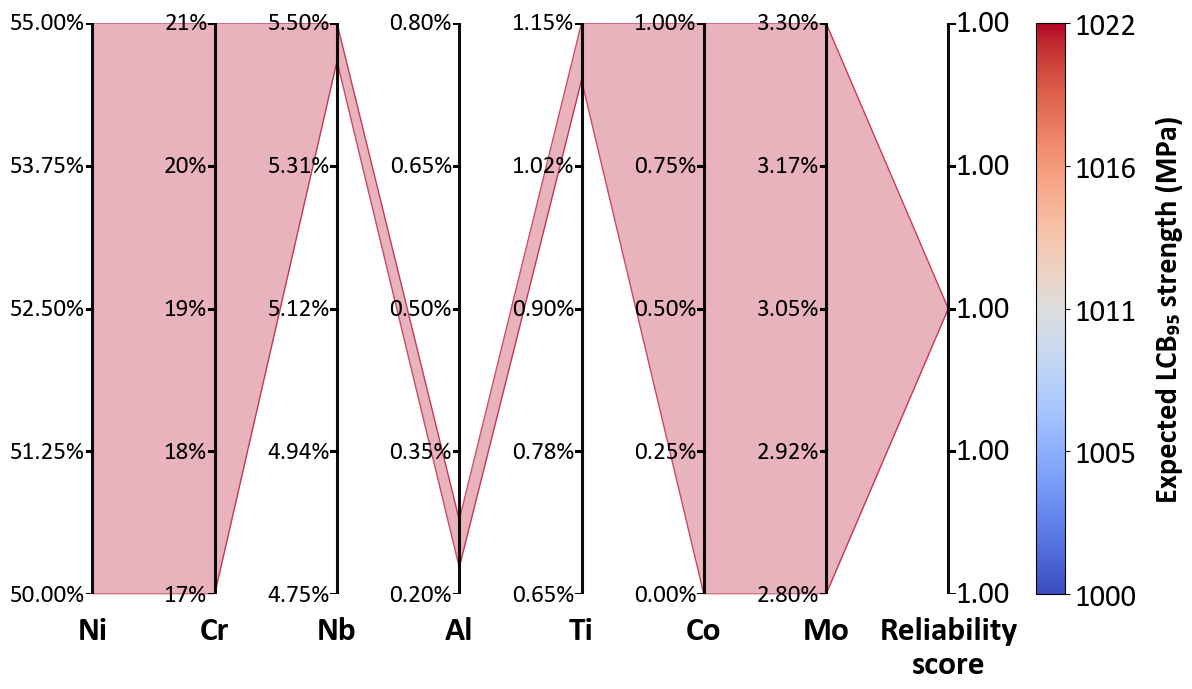

In [11]:
from __future__ import annotations

import math
import pickle
from pathlib import Path
from typing import Dict, Optional, Tuple

import matplotlib.cm as cm
import matplotlib.colors as mcolors
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.font_manager import FontProperties

from baybe import Campaign
from baybe.constraints import ContinuousLinearInequalityConstraint
from baybe.objective import DesirabilityObjective
from baybe.parameters import NumericalContinuousParameter
from baybe.recommenders import BotorchRecommender, RandomRecommender, TwoPhaseMetaRecommender
from baybe.searchspace import SearchSpace
from baybe.targets import NumericalTarget

np.random.seed(42)

# ----------------------------
# Configuration
# ----------------------------
ELEMENTS: Tuple[str, ...] = ("Ni", "Cr", "Nb", "Al", "Ti", "Co", "Mo")

DATASET_PATH = Path(
    "C:/Users/hasan/Uncertainty-aware-inverse-design-of-alloys/data/Example dataset of Alloy 718 strength.csv"
)
SURROGATE_MODEL_PATH = Path(
    "C:/Users/hasan/Uncertainty-aware-inverse-design-of-alloys/model/pce_surrogate.pkl"
)

DEFAULT_NUM_MC_SAMPLES = 1000
DEFAULT_SIGMA_MODEL = 32.417
DEFAULT_Z_INNER = 1.645

# Fixed global ranges used for the 4 non-optimized elements in the 3-element design workflow
DEFAULT_RANGES_WT = {
    "Ni": (50.0, 55.0),
    "Cr": (17.0, 21.0),
    "Nb": (4.75, 5.50),
    "Al": (0.2, 0.8),
    "Ti": (0.65, 1.15),
    "Co": (0.0, 1.0),
    "Mo": (2.8, 3.3),
}

OUTPUT_DIR = Path("outputs")


# ---------------------------------------------------------
# 1) Loading helpers
# ---------------------------------------------------------
def load_dataset_for_bounds(path: Path) -> pd.DataFrame:
    if not path.exists():
        raise FileNotFoundError(f"Dataset file not found: {path.resolve()}")
    return pd.read_csv(path)


def load_surrogate_model(path: Path):
    if not path.exists():
        raise FileNotFoundError(f"Surrogate model not found: {path.resolve()}")
    with open(path, "rb") as f:
        return pickle.load(f)


# ---------------------------------------------------------
# 2) Helper functions: Wilson / sampling / QoI calculations
# ---------------------------------------------------------
def _wilson_lower_95(p_hat: float, n: int) -> float:
    """Wilson score lower bound (95% CI) for a binomial proportion."""
    if n <= 0:
        return 0.0
    z = 1.959963984540054  # 95% two-sided
    denom = 1.0 + z**2 / n
    center = (p_hat + z**2 / (2 * n)) / denom
    radius = (z / denom) * math.sqrt((p_hat * (1 - p_hat) + z**2 / (4 * n)) / n)
    return max(0.0, center - radius)


def _uniform_range(lo: float, hi: float, n: int) -> np.ndarray:
    lo = float(lo)
    hi = float(hi)
    if hi < lo:
        lo, hi = hi, lo
    return np.random.uniform(lo, hi, int(n))


def suggest_range_with_coverage_3elem(
    dataframe: pd.DataFrame,
    num_samples: int,
    model,
    sigma_model: float,
    target_YS: float = 1000.0,
    z_inner: float = DEFAULT_Z_INNER,
    fixed_ranges_wt: dict[str, tuple[float, float]] = DEFAULT_RANGES_WT,
) -> tuple[list, list, list, list, list, list]:
    """
    3-element design:
      optimized: Nb, Al, Ti (from candidate box)
      fixed global sampling: Ni, Cr, Co, Mo (from fixed_ranges_wt constants)
    """
    required = ["Nb_min", "Nb_max", "Al_min", "Al_max", "Ti_min", "Ti_max"]
    missing = [c for c in required if c not in dataframe.columns]
    if missing:
        raise KeyError(f"3-element candidate dataframe missing required columns: {missing}")

    Ni_range = fixed_ranges_wt["Ni"]
    Cr_range = fixed_ranges_wt["Cr"]
    Co_range = fixed_ranges_wt["Co"]
    Mo_range = fixed_ranges_wt["Mo"]

    mean_strength, sigma_prop, sigma_total = [], [], []
    lb05_over_box, coverage_prop, coverage_lb = [], [], []

    sigma_model = float(sigma_model)
    target_YS = float(target_YS)

    for _, row in dataframe.iterrows():
        Nb = _uniform_range(row["Nb_min"], row["Nb_max"], num_samples)
        Al = _uniform_range(row["Al_min"], row["Al_max"], num_samples)
        Ti = _uniform_range(row["Ti_min"], row["Ti_max"], num_samples)

        Ni = np.random.uniform(*Ni_range, num_samples)
        Cr = np.random.uniform(*Cr_range, num_samples)
        Co = np.random.uniform(*Co_range, num_samples)
        Mo = np.random.uniform(*Mo_range, num_samples)

        X = np.vstack([Ni, Cr, Nb, Al, Ti, Co, Mo]).T  # (N,7) in ELEMENTS order

        mu_i = np.asarray(model(*X.T), dtype=float).reshape(-1)

        lcb_i = mu_i - z_inner * sigma_model
        safe = (lcb_i >= target_YS)

        p_hat = float(np.mean(safe))
        p_lb = _wilson_lower_95(p_hat, len(mu_i))

        q05_lb = float(np.quantile(lcb_i, 0.05))

        s_comp = float(np.std(mu_i, ddof=1))
        s_tot = math.sqrt(s_comp**2 + sigma_model**2)

        mean_strength.append(float(np.mean(mu_i)))
        sigma_prop.append(s_comp)
        sigma_total.append(s_tot)
        lb05_over_box.append(q05_lb)
        coverage_prop.append(p_hat)
        coverage_lb.append(p_lb)

    return (
        mean_strength,
        sigma_prop,
        sigma_total,
        lb05_over_box,
        coverage_prop,
        coverage_lb,
    )


# ---------------------------------------------------------
# 3) BayBE: search space + campaign (3 elements only)
# ---------------------------------------------------------
def build_searchspace_3elem(
    df: pd.DataFrame,
    *,
    min_deltas: dict[str, float],
) -> SearchSpace:
    """
    Search space for Nb–Al–Ti only, bounds derived from dataset columns.
    min_deltas only used for Nb/Al/Ti constraints.
    """
    def _bounds(col: str) -> tuple[float, float]:
        a = pd.to_numeric(df[col], errors="coerce").to_numpy(dtype=float)
        lo = float(np.nanmin(a))
        hi = float(np.nanmax(a))
        if not np.isfinite(lo) or not np.isfinite(hi) or hi <= lo:
            raise ValueError(f"Bad bounds for column '{col}': lo={lo}, hi={hi}")
        return lo, hi

    params = []
    for el in ("Nb", "Al", "Ti"):
        lo, hi = _bounds(f"{el} (wt%)")
        params.append(NumericalContinuousParameter(f"{el}_min", bounds=(lo, hi)))
        params.append(NumericalContinuousParameter(f"{el}_max", bounds=(lo, hi)))

    constraints = []
    for el in ("Nb", "Al", "Ti"):
        eps = float(min_deltas[el])
        if eps <= 0:
            raise ValueError(f"Minimum allowable difference for {el} must be > 0. Got {eps}.")
        constraints.append(
            ContinuousLinearInequalityConstraint(
                parameters=[f"{el}_max", f"{el}_min"],
                coefficients=[1.0, -1.0],
                rhs=eps,
            )
        )

    return SearchSpace.from_product(parameters=params, constraints=constraints)


def build_campaign(
    space: SearchSpace,
    *,
    min_required_strength: float,
    sigma_threshold: float,
    reliability_target: float,
    weights: Tuple[float, float, float],
) -> Campaign:
    min_required_strength = float(min_required_strength)
    sigma_threshold = float(sigma_threshold)
    reliability_target = float(reliability_target)

    if sigma_threshold <= 0:
        raise ValueError("sigma_threshold must be > 0.")
    if not (0.0 < reliability_target <= 1.0):
        raise ValueError("reliability_target must be in (0, 1].")

    w1, w2, w3 = map(float, weights)
    wsum = w1 + w2 + w3
    if wsum <= 0:
        raise ValueError("Weights must sum to a positive value.")
    weights_norm = [w1 / wsum, w2 / wsum, w3 / wsum]

    lb_lo = min_required_strength
    lb_hi = min_required_strength + 0.5 * sigma_threshold

    obj_1 = NumericalTarget(
        name="Total uncertainty",
        mode="MIN",
        bounds=(0.0, sigma_threshold),
        transformation="LINEAR",
    )
    obj_2 = NumericalTarget(
        name="Coverage over box p_x",
        mode="MATCH",
        bounds=(reliability_target, 1.0),
        transformation="TRIANGULAR",
    )
    obj_3 = NumericalTarget(
        name="Percentile LB over box (5%) (MPa)",
        mode="MATCH",
        bounds=(lb_lo, lb_hi),
        transformation="BELL",
    )

    objective = DesirabilityObjective(
        targets=[obj_1, obj_2, obj_3],
        weights=weights_norm,
        scalarizer="GEOM_MEAN",
    )

    recommender = TwoPhaseMetaRecommender(
        initial_recommender=RandomRecommender(),
        recommender=BotorchRecommender(acquisition_function="qLogEI"),
    )

    return Campaign(searchspace=space, objective=objective, recommender=recommender)


# ---------------------------------------------------------
# 4) Run Bayesian optimization (3 elements)
# ---------------------------------------------------------
def run_bayesian_optimization_3elem(
    campaign: Campaign,
    model,
    *,
    n_iters: int,
    batch_size: int,
    num_mc_samples: int,
    target_YS: float,
    sigma_model: float,
    z_inner: float,
    lb_window: Tuple[float, float],
    sigma_max: float,
    coverage_min: Optional[float],
    fixed_ranges_wt: dict[str, tuple[float, float]] = DEFAULT_RANGES_WT,
) -> Tuple[pd.DataFrame, pd.DataFrame]:
    if n_iters <= 0:
        raise ValueError("n_iters must be positive.")
    if batch_size <= 0:
        raise ValueError("batch_size must be positive.")
    if num_mc_samples <= 0:
        raise ValueError("num_mc_samples must be positive.")

    for k in range(n_iters):
        print(f"Running BO iteration {k + 1}/{n_iters}")
        iter_df = campaign.recommend(batch_size=batch_size)

        mu, s_comp, s_tot, lb5, cover_p, cover_lb = suggest_range_with_coverage_3elem(
            dataframe=iter_df,
            num_samples=num_mc_samples,
            model=model,
            sigma_model=sigma_model,
            target_YS=target_YS,
            z_inner=z_inner,
            fixed_ranges_wt=fixed_ranges_wt,
        )

        # inject fixed min/max columns so downstream filtering/plotting is identical to 7-element workflow
        for el in ("Ni", "Cr", "Co", "Mo"):
            iter_df[f"{el}_min"] = fixed_ranges_wt[el][0]
            iter_df[f"{el}_max"] = fixed_ranges_wt[el][1]

        iter_df["Predicted yield strength (MPa)"] = mu
        iter_df["Compositional variation"] = s_comp
        iter_df["Total uncertainty"] = s_tot
        iter_df["Percentile LB over box (5%) (MPa)"] = lb5
        iter_df["Coverage over box p_x"] = cover_p
        iter_df["Coverage over box LB (95% CI)"] = cover_lb

        campaign.add_measurements(iter_df)

    full_data = campaign.measurements.copy()

    mask = (
        full_data["Percentile LB over box (5%) (MPa)"].between(lb_window[0], lb_window[1], inclusive="both")
        & (full_data["Total uncertainty"] <= float(sigma_max))
    )
    if coverage_min is not None:
        mask &= (full_data["Coverage over box p_x"] >= float(coverage_min))

    filtered_data = (
        full_data.loc[mask]
        .sort_values("Total uncertainty", ascending=True)
        .reset_index(drop=True)
    )

    return full_data, filtered_data


# ---------------------------------------------------------
# 5) Pareto front analysis (2D)
# ---------------------------------------------------------
def pareto_front_2d(
    df: pd.DataFrame,
    xcol: str,
    ycol: str,
    maximize_x: bool = True,
    eps_y: float = 0.2,
) -> Tuple[pd.DataFrame, np.ndarray]:
    if df.empty:
        return df.copy(), np.zeros(0, dtype=bool)

    work = df[[xcol, ycol]].copy()
    work[xcol] = pd.to_numeric(work[xcol], errors="coerce")
    work[ycol] = pd.to_numeric(work[ycol], errors="coerce")
    valid = work.dropna()

    if valid.empty:
        return df.iloc[0:0].copy(), np.zeros(len(df), dtype=bool)

    arr = valid.to_numpy(dtype=float)
    order = np.argsort(-arr[:, 0]) if maximize_x else np.argsort(arr[:, 0])
    y_sorted = arr[order, 1]

    keep_pos = []
    best_y = np.inf
    for k, pos in enumerate(order):
        if y_sorted[k] < best_y - float(eps_y):
            keep_pos.append(pos)
            best_y = y_sorted[k]

    pareto_valid_index = valid.index[np.array(keep_pos, dtype=int)]
    mask = df.index.isin(pareto_valid_index)
    front = df.loc[mask].copy().sort_values(by=xcol, ascending=True)
    return front, np.asarray(mask, dtype=bool)


# ---------------------------------------------------------
# 6) Coordinate plot for ONE row (same as your reference style)
# ---------------------------------------------------------
def plot_coordinate_plot_single_row_like_reference(
    row: pd.Series,
    *,
    pareto_df: pd.DataFrame,
    target_YS: float,
    out_path: Path | None = None,
    elements: list[str] | None = None,
    ranges_wt: dict[str, tuple[float, float]] | None = None,
    strength_col: str = "Percentile LB over box (5%) (MPa)",
    coverage_candidates: tuple[str, ...] = ("Coverage over p_box", "Coverage over box p_x"),
    prop_axis_label: str = "Reliability\nscore",
    cb_label: str = "Expected LCB₉₅ strength (MPa)",
    fig_size: tuple[float, float] = (12.5, 7.0),
    co_ticks: np.ndarray | None = None,
    co_tick_format: str | None = "{:.2f}%",
) -> plt.Figure:
    if elements is None:
        elements = list(ELEMENTS)
    if ranges_wt is None:
        ranges_wt = DEFAULT_RANGES_WT

    coverage_col = None
    for cname in coverage_candidates:
        if cname in pareto_df.columns:
            coverage_col = cname
            break
    if coverage_col is None:
        raise KeyError(f"No coverage column found in pareto_df. Tried: {list(coverage_candidates)}")

    missing = []
    for el in elements:
        for suf in ("_min", "_max"):
            c = f"{el}{suf}"
            if c not in row.index:
                missing.append(c)
    if missing:
        raise KeyError(f"Selected row is missing required range columns: {missing}")

    plot_df = pd.DataFrame([row]).copy()
    plot_df[strength_col] = pd.to_numeric(plot_df[strength_col], errors="coerce")
    plot_df[coverage_col] = pd.to_numeric(plot_df[coverage_col], errors="coerce")

    plt.rcParams["font.family"] = "calibri"
    cmap = cm.coolwarm

    pareto_strength = pd.to_numeric(pareto_df.get(strength_col, pd.Series([], dtype=float)), errors="coerce").to_numpy(
        dtype=float
    )
    vmax_ref = float(np.nanmax(pareto_strength)) if pareto_strength.size else float(plot_df[strength_col].iloc[0])
    if not np.isfinite(vmax_ref):
        vmax_ref = float(plot_df[strength_col].iloc[0])

    vmin = float(target_YS)
    vmax = float(max(vmin + 1e-6, vmax_ref))
    cnorm = mcolors.Normalize(vmin=vmin, vmax=vmax)
    strength_cbar_ticks = np.linspace(vmin, vmax, 5)

    X_LABEL_FONT = {"size": 24, "weight": "bold", "color": "black"}
    X_LABEL_PAD = 16

    AX_TICK_FONT = {"size": 22, "weight": "normal", "color": "black"}
    TICK_LEN = 0.045
    TICK_LW = 2.2
    TICK_COLOR = "black"
    LABEL_DX_LEFT = 0.060
    LABEL_DX_RIGHT = 0.060

    if co_ticks is None:
        co_ticks = np.array([0.00, 0.25, 0.50, 0.75, 1.00], dtype=float)

    def to_axis_units(v, el):
        v = float(v)
        hi = ranges_wt[el][1]
        if v <= 1.5 and hi > 2.0:
            return v * 180.0
        return v

    def norm_to_range(value, lo, hi):
        return (np.asarray(value, float) - lo) / (hi - lo + 1e-12)

    axis_ticks = {el: np.linspace(ranges_wt[el][0], ranges_wt[el][1], 5) for el in elements}
    axis_ticks["Co"] = np.asarray(co_ticks, float)

    prop_axis_name = "LB (5%)"

    def get_ticks_for_axis(name, lo, hi):
        if name == prop_axis_name:
            return np.linspace(lo, hi, 5)
        return np.asarray(axis_ticks.get(name, np.linspace(lo, hi, 5)), float)

    def format_tick_label(name, t_val, ticks):
        if name == prop_axis_name:
            return f"{t_val:.2f}"
        if name == "Co" and co_tick_format:
            return co_tick_format.format(t_val)
        return "{:.0f}%".format(t_val) if np.allclose(ticks, np.round(ticks), atol=1e-9) else "{:.2f}%".format(t_val)

    axis_labels = elements + [prop_axis_label]
    prop_axis_index = len(elements)

    cov_vals = pd.to_numeric(pareto_df[coverage_col], errors="coerce").to_numpy(dtype=float)
    vmin_prop = float(np.nanmin(cov_vals))
    vmax_prop = float(np.nanmax(cov_vals))
    if not np.isfinite(vmin_prop) or not np.isfinite(vmax_prop):
        vmin_prop, vmax_prop = 0.0, 1.0
    if vmin_prop == vmax_prop:
        eps = max(1e-6, 1e-6 * max(1.0, abs(vmin_prop)))
        vmin_prop -= eps
        vmax_prop += eps
    pad = 0.02 * (vmax_prop - vmin_prop + 1e-12)
    prop_range = (vmin_prop - pad, vmax_prop + pad)

    x = np.arange(len(axis_labels))
    fig, ax = plt.subplots(figsize=fig_size)

    for _, r in plot_df.iterrows():
        y_min, y_max = [], []

        for el in elements:
            vmin_el = to_axis_units(r[f"{el}_min"], el)
            vmax_el = to_axis_units(r[f"{el}_max"], el)
            y_min.append(norm_to_range(vmin_el, *ranges_wt[el]))
            y_max.append(norm_to_range(vmax_el, *ranges_wt[el]))

        cov_val = float(r[coverage_col])
        y_prop = norm_to_range(cov_val, *prop_range)
        y_min.append(y_prop)
        y_max.append(y_prop)

        y_min = np.array(y_min, float)
        y_max = np.array(y_max, float)
        y_lo = np.minimum(y_min, y_max)
        y_hi = np.maximum(y_min, y_max)

        color = cmap(cnorm(float(r[strength_col])))
        ax.fill_between(x, y_lo, y_hi, color=color, alpha=0.30, linewidth=0)
        ax.plot(x, y_lo, color=color, alpha=0.7, linewidth=1.0)
        ax.plot(x, y_hi, color=color, alpha=0.7, linewidth=1.0)

    ax.set_xlim(-0.25, len(axis_labels) - 0.75)
    ax.set_ylim(0, 1)
    ax.set_yticks([])

    ax.set_xticks(x)
    texts = ax.set_xticklabels(axis_labels)
    for t in texts:
        t.set_fontsize(X_LABEL_FONT["size"])
        t.set_fontweight(X_LABEL_FONT["weight"])
        t.set_color(X_LABEL_FONT["color"])
    ax.tick_params(axis="x", length=0, pad=X_LABEL_PAD)

    for side in ("left", "right", "top", "bottom"):
        ax.spines[side].set_visible(False)

    for xi in x:
        ax.vlines(xi, 0, 1, color="black", linewidth=2.2, alpha=0.95)

    for xi, nm_display in enumerate(axis_labels):
        is_prop = (xi == prop_axis_index)
        name_for_logic = prop_axis_name if is_prop else nm_display

        if is_prop:
            lo, hi = prop_range
        else:
            lo, hi = ranges_wt[name_for_logic]

        ticks = get_ticks_for_axis(name_for_logic, lo, hi)
        y_ticks = (ticks - lo) / (hi - lo + 1e-12)

        if is_prop:
            for t_val, yv in zip(ticks, y_ticks):
                ax.plot([xi, xi + TICK_LEN], [yv, yv], color=TICK_COLOR, linewidth=TICK_LW)
                ax.text(
                    xi + LABEL_DX_RIGHT,
                    yv,
                    format_tick_label(name_for_logic, t_val, ticks),
                    ha="left",
                    va="center",
                    fontsize=AX_TICK_FONT["size"],
                    fontweight=AX_TICK_FONT["weight"],
                    color=AX_TICK_FONT["color"],
                    clip_on=False,
                )
        else:
            for t_val, yv in zip(ticks, y_ticks):
                ax.plot([xi - TICK_LEN, xi], [yv, yv], color=TICK_COLOR, linewidth=TICK_LW)
                ax.text(
                    xi - LABEL_DX_LEFT,
                    yv,
                    format_tick_label(name_for_logic, t_val, ticks),
                    ha="right",
                    va="center",
                    fontsize=AX_TICK_FONT["size"] - 4,
                    fontweight=AX_TICK_FONT["weight"],
                    color=AX_TICK_FONT["color"],
                    clip_on=False,
                )

    subset_vals = plot_df[strength_col].to_numpy(float)
    extend = (
        "both"
        if (np.nanmin(subset_vals) < vmin and np.nanmax(subset_vals) > vmax)
        else "min"
        if np.nanmin(subset_vals) < vmin
        else "max"
        if np.nanmax(subset_vals) > vmax
        else "neither"
    )

    plt.subplots_adjust(left=0.22, right=0.90, bottom=0.16)
    sm = cm.ScalarMappable(norm=cnorm, cmap=cmap)
    cbar = plt.colorbar(sm, ax=ax, pad=0.05, extend=extend)

    cb_label_props = FontProperties(size=22, weight="bold")
    cbar.ax.set_ylabel(cb_label, fontproperties=cb_label_props, rotation=90, labelpad=14)

    cbar.ax.tick_params(labelsize=22, labelcolor="black")
    for lbl in cbar.ax.get_yticklabels():
        lbl.set_fontweight("normal")

    cbar.set_ticks(strength_cbar_ticks)
    cbar.set_ticklabels([f"{t:.0f}" for t in strength_cbar_ticks])

    plt.tight_layout()

    if out_path is not None:
        out_path.parent.mkdir(parents=True, exist_ok=True)
        fig.savefig(out_path, dpi=300, bbox_inches="tight")

    return fig


# ---------------------------------------------------------
# 7) CLI prompts + main
# ---------------------------------------------------------
def _prompt_float(prompt: str, default: float | None = None) -> float:
    while True:
        raw = input(f"{prompt}" + (f" [default={default}]: " if default is not None else ": ")).strip()
        if raw == "" and default is not None:
            return float(default)
        try:
            return float(raw)
        except ValueError:
            print("Please enter a valid number.")


def _prompt_int(prompt: str, default: int | None = None) -> int:
    while True:
        raw = input(f"{prompt}" + (f" [default={default}]: " if default is not None else ": ")).strip()
        if raw == "" and default is not None:
            return int(default)
        try:
            v = int(raw)
            if v <= 0:
                print("Please enter a positive integer.")
                continue
            return v
        except ValueError:
            print("Please enter a valid integer.")


def _prompt_weights(default=(0.5, 0.3, 0.2)) -> Tuple[float, float, float]:
    while True:
        raw = input(f"Enter objective weights w1,w2,w3 [default={default}]: ").strip()
        if raw == "":
            return (float(default[0]), float(default[1]), float(default[2]))
        parts = [p.strip() for p in raw.split(",")]
        if len(parts) != 3:
            print("Please enter exactly 3 comma-separated numbers, e.g., 0.5,0.3,0.2")
            continue
        try:
            w = tuple(float(p) for p in parts)
            if sum(w) <= 0:
                print("Weights must sum to a positive value.")
                continue
            return w
        except ValueError:
            print("Please enter valid numbers for weights.")


def _prompt_min_deltas_3elem() -> Dict[str, float]:
    """
    Prompts min allowable (max-min) differences ONLY for Nb, Al, Ti.

    You can enter:
      - one number: applies to all 3
      - three comma-separated numbers: Nb,Al,Ti
    """
    while True:
        raw = input(
            "Minimum allowable difference (max-min) for Nb,Al,Ti. "
            "Enter one value for all, or 3 comma-separated values (Nb,Al,Ti) [default=0.01]: "
        ).strip()
        if raw == "":
            return {"Nb": 0.01, "Al": 0.01, "Ti": 0.01}

        parts = [p.strip() for p in raw.split(",") if p.strip() != ""]
        try:
            if len(parts) == 1:
                v = float(parts[0])
                if v <= 0:
                    print("Value must be > 0.")
                    continue
                return {"Nb": v, "Al": v, "Ti": v}
            if len(parts) == 3:
                vals = [float(p) for p in parts]
                if any(v <= 0 for v in vals):
                    print("All values must be > 0.")
                    continue
                return {"Nb": vals[0], "Al": vals[1], "Ti": vals[2]}
            print("Please enter either 1 value or exactly 3 comma-separated values.")
        except ValueError:
            print("Please enter valid numeric values.")


def _prompt_plot_row_index(n_rows: int) -> Optional[int]:
    while True:
        raw = input(
            f"\nEnter a filtered_df row index to plot (0..{n_rows-1}), "
            "or press Enter / type 'q' / type 'esc' to skip: "
        )
        if raw is None:
            return None
        s = raw.strip().lower()
        if s in ("", "q", "quit", "esc", "escape"):
            return None
        try:
            idx = int(s)
            if 0 <= idx < n_rows:
                return idx
            print("Index out of range.")
        except ValueError:
            print("Please enter a valid integer index, or Enter/q/esc to skip.")


def main() -> None:
    df_bounds = load_dataset_for_bounds(DATASET_PATH)
    surrogate_model = load_surrogate_model(SURROGATE_MODEL_PATH)

    min_required_strength = _prompt_float("Minimum required strength (MPa)", default=1000.0)
    sigma_threshold = _prompt_float("Allowable total uncertainty threshold (MPa)", default=45.0)
    reliability_pct = _prompt_float("Target reliability (%)", default=95.0)

    reliability_target = reliability_pct / 100.0 if reliability_pct > 1.0 else reliability_pct
    if not (0.0 < reliability_target <= 1.0):
        raise ValueError("Reliability must be given as 0-1 or 0-100%.")

    weights = _prompt_weights(default=(0.5, 0.3, 0.2))

    n_iters = _prompt_int("Number of BO iterations", default=10)
    batch_size = _prompt_int("Batch size per iteration", default=10)

    # IMPORTANT: only for Nb/Al/Ti
    min_deltas = _prompt_min_deltas_3elem()

    num_mc_samples = DEFAULT_NUM_MC_SAMPLES
    sigma_model = DEFAULT_SIGMA_MODEL
    z_inner = DEFAULT_Z_INNER

    lb_lo = float(min_required_strength)
    lb_hi = float(min_required_strength + 0.5 * sigma_threshold)
    lb_window = (lb_lo, lb_hi)

    target_YS = float(min_required_strength)
    sigma_max = float(sigma_threshold)
    coverage_min = float(reliability_target)

    space = build_searchspace_3elem(df_bounds, min_deltas=min_deltas)
    campaign = build_campaign(
        space,
        min_required_strength=min_required_strength,
        sigma_threshold=sigma_threshold,
        reliability_target=reliability_target,
        weights=weights,
    )

    OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

    full_df, filtered_df = run_bayesian_optimization_3elem(
        campaign=campaign,
        model=surrogate_model,
        n_iters=n_iters,
        batch_size=batch_size,
        num_mc_samples=num_mc_samples,
        target_YS=target_YS,
        sigma_model=sigma_model,
        z_inner=z_inner,
        lb_window=lb_window,
        sigma_max=sigma_max,
        coverage_min=coverage_min,
        fixed_ranges_wt=DEFAULT_RANGES_WT,  # fixed Ni/Cr/Co/Mo ranges
    )

    full_path = OUTPUT_DIR / "bo_measurements_full.csv"
    filt_path = OUTPUT_DIR / "pareto_filtered.csv"
    full_df.to_csv(full_path, index=False)
    filtered_df.to_csv(filt_path, index=False)

    print(f"\nSaved: {full_path}")
    print(f"Saved: {filt_path}")

    if filtered_df.empty:
        print("\nNo candidates satisfied the filter criteria.")
        print(
            f"Filter used: LCB5% in [{lb_window[0]:.2f}, {lb_window[1]:.2f}] MPa, "
            f"Total uncertainty <= {sigma_max:.2f} MPa, Coverage >= {coverage_min:.3f}"
        )
        return

    xcol = "Percentile LB over box (5%) (MPa)"
    ycol = "Total uncertainty"

    pareto_df, _ = pareto_front_2d(filtered_df, xcol=xcol, ycol=ycol, maximize_x=True, eps_y=0.2)
    pareto_path = OUTPUT_DIR / "pareto_front.csv"
    pareto_df.to_csv(pareto_path, index=False)
    print(f"Saved (not displayed): {pareto_path}")

    pd.set_option("display.max_rows", 200)
    pd.set_option("display.max_columns", 200)
    pd.set_option("display.width", 200)

    print("\nFiltered dataset (final output):")
    print(filtered_df)

    idx = _prompt_plot_row_index(len(filtered_df))
    if idx is None:
        print("No plot requested. Exiting.")
        return

    row = filtered_df.iloc[idx]
    fig_path = OUTPUT_DIR / f"coordinate_plot_row_{idx}.png"
    fig = plot_coordinate_plot_single_row_like_reference(
        row,
        pareto_df=pareto_df,
        target_YS=target_YS,
        out_path=fig_path,
        strength_col=xcol,
        coverage_candidates=("Coverage over p_box", "Coverage over box p_x"),
        prop_axis_label="Reliability\nscore",
        cb_label="Expected LCB₉₅ strength (MPa)",
    )
    print(f"Saved plot: {fig_path}")
    plt.show()
    plt.close(fig)


if __name__ == "__main__":
    main()


In [15]:
full_df = pd.read_csv("C:/Users/hasan/Uncertainty-aware-inverse-design-of-alloys/Demo/outputs/bo_measurements_full.csv")
full_df.sort_values(by='Total uncertainty', ascending=True)

,Nb_min,Nb_max,Al_min,Al_max,Ti_min,Ti_max,Ni_min,Ni_max,Cr_min,Cr_max,Co_min,Co_max,Mo_min,Mo_max,Predicted yield strength (MPa),Compositional variation,Total uncertainty,Percentile LB over box (5%) (MPa),Coverage over box p_x,Coverage over box LB (95% CI),BatchNr,FitNr
27,5.449837,5.499837,0.200014,0.250014,0.650073,0.700073,50.0,55.0,17.0,21.0,0.0,1.0,2.8,3.3,891.946008,22.473836,39.445344,801.948091,0.000,2.168404e-19,3,3.0
23,5.449837,5.499837,0.200014,0.250014,0.908541,0.958541,50.0,55.0,17.0,21.0,0.0,1.0,2.8,3.3,1010.035277,22.675078,39.560347,919.517608,0.027,1.862138e-02,3,3.0
38,5.389789,5.439789,0.200014,0.250014,1.099920,1.149920,50.0,55.0,17.0,21.0,0.0,1.0,2.8,3.3,1086.828524,23.045714,39.773947,994.932383,0.916,8.971750e-01,4,4.0
24,5.449837,5.499837,0.228090,0.278090,1.099920,1.149920,50.0,55.0,17.0,21.0,0.0,1.0,2.8,3.3,1115.106592,23.616841,40.107569,1021.868780,0.997,9.912170e-01,3,3.0
48,5.187300,5.325553,0.201036,0.252699,1.030718,1.091441,50.0,55.0,17.0,21.0,0.0,1.0,2.8,3.3,1053.291545,23.988306,40.327419,959.104723,0.494,4.630948e-01,5,5.0
46,5.382672,5.432673,0.200014,0.250014,1.084755,1.149920,50.0,55.0,17.0,21.0,0.0,1.0,2.8,3.3,1081.605271,24.211780,40.460749,989.187994,0.884,8.626667e-01,5,5.0
12,5.449837,5.499837,0.200014,0.250014,1.099920,1.149920,50.0,55.0,17.0,21.0,0.0,1.0,2.8,3.3,1087.903019,24.289190,40.507119,995.968899,0.917,8.982635e-01,2,2.0
37,4.821350,5.391884,0.200015,0.250705,0.933055,0.993694,50.0,55.0,17.0,21.0,0.0,1.0,2.8,3.3,1006.016693,24.530030,40.651990,910.865662,0.025,1.699013e-02,4,4.0
13,4.750029,4.800029,0.200014,0.250014,1.099920,1.149920,50.0,55.0,17.0,21.0,0.0,1.0,2.8,3.3,1054.989263,25.189483,41.053282,963.362866,0.497,4.660816e-01,2,2.0
14,4.750029,5.499837,0.200014,0.250014,1.099920,1.149920,50.0,55.0,17.0,21.0,0.0,1.0,2.8,3.3,1070.871219,25.768014,41.410777,977.110028,0.731,7.026702e-01,2,2.0
